# Klasifikasi Diabetes dengan C4.5 (Decision Tree)
### Dataset: `diabetes_012_health_indicators_BRFSS2015.csv`

**Alur sederhana:**
1. Load dataset
2. EDA singkat (cek ukuran, missing value, distribusi kelas)
3. Preprocessing: hapus duplikat + ubah ke biner (Diabetes vs Tidak)
4. Split data train/test
5. **Balancing** kelas pada data training (undersampling)
6. Training model **C4.5** (Decision Tree dengan `criterion='entropy'`)
7. Evaluasi model
8. Visualisasi pohon keputusan & feature importance

## 1. Import Library

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, roc_auc_score,roc_curve, auc)
import pickle



## 2. Load Dataset

In [17]:
df = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
print(f"Ukuran data: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Ukuran data: 253680 baris, 22 kolom


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 3. EDA Singkat

In [18]:
# Cek missing value
print("Jumlah missing value per kolom:")
print(df.isnull().sum().sum(), "total missing value")

# Distribusi kelas awal (3 kelas)
print("\nDistribusi kelas asli (Diabetes_012):")
print(df['Diabetes_012'].value_counts().rename({0.0:'Tidak Diabetes', 1.0:'Prediabetes', 2.0:'Diabetes'}))

Jumlah missing value per kolom:
0 total missing value

Distribusi kelas asli (Diabetes_012):
Diabetes_012
Tidak Diabetes    213703
Diabetes           35346
Prediabetes         4631
Name: count, dtype: int64


## 4. Preprocessing

Langkah sederhana:
1. **Hapus duplikat** — banyak baris survei yang identik.
2. **Ubah ke biner** — gabungkan *Prediabetes (1)* dan *Diabetes (2)* menjadi satu kelas **Diabetes (1)**, sisanya **Tidak Diabetes (0)**. Sesuai tujuan: membedakan "ya diabetes" vs "tidak diabetes".

In [19]:
# 4a. Hapus duplikat
sebelum = len(df)
df = df.drop_duplicates()
print(f"Duplikat dihapus: {sebelum - len(df)} baris  ->  sisa {len(df)} baris")

# 4b. Ubah label ke biner: 0 = tidak diabetes, 1 = diabetes (prediabetes + diabetes)
df['Diabetes'] = (df['Diabetes_012'] > 0).astype(int)
df = df.drop(columns=['Diabetes_012'])

print("\nDistribusi kelas biner:")
print(df['Diabetes'].value_counts().rename({0:'Tidak Diabetes (0)', 1:'Diabetes (1)'}))
rasio = df['Diabetes'].value_counts()[0] / df['Diabetes'].value_counts()[1]
print(f"\nRasio ketidakseimbangan: {rasio:.1f} : 1  (perlu di-balance)")

Duplikat dihapus: 23899 baris  ->  sisa 229781 baris

Distribusi kelas biner:
Diabetes
Tidak Diabetes (0)    190055
Diabetes (1)           39726
Name: count, dtype: int64

Rasio ketidakseimbangan: 4.8 : 1  (perlu di-balance)


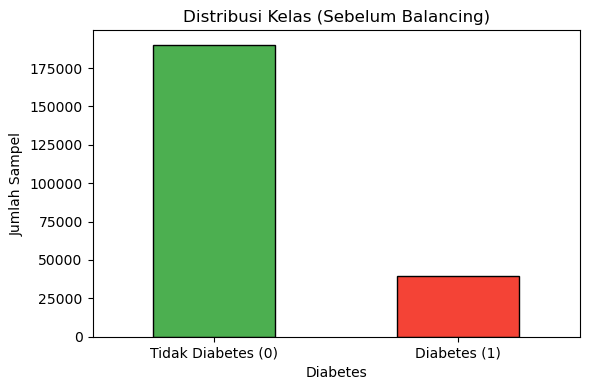

In [20]:
# Visualisasi distribusi sebelum balancing
fig, ax = plt.subplots(figsize=(6,4))
df['Diabetes'].value_counts().sort_index().plot(
    kind='bar', ax=ax, color=['#4CAF50','#F44336'], edgecolor='black')
ax.set_xticklabels(['Tidak Diabetes (0)', 'Diabetes (1)'], rotation=0)
ax.set_title('Distribusi Kelas (Sebelum Balancing)')
ax.set_ylabel('Jumlah Sampel')
plt.tight_layout(); plt.savefig('01_distribusi_sebelum.png', dpi=150); plt.show()

In [21]:
# FEATURE SELECTION: hanya pakai 5 fitur paling berpengaruh
# (berdasarkan feature importance pada model 21 fitur)
FEATURES = ['HighBP', 'HighChol', 'BMI', 'GenHlth', 'Age']
X = df[FEATURES]
y = df['Diabetes']
print('Fitur yang dipakai:', FEATURES)

Fitur yang dipakai: ['HighBP', 'HighChol', 'BMI', 'GenHlth', 'Age']


## 5. Split Data (Train / Test)

Data dibagi **80% training** dan **20% testing**. Balancing dilakukan **hanya pada data training** supaya data testing tetap mencerminkan kondisi nyata (menghindari *data bocor* / data leakage).

In [22]:
# Pakai 5 fitur hasil seleksi di atas (jangan ditimpa dengan semua kolom)
X = df[FEATURES]
y = df['Diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Data training : {X_train.shape[0]} baris")
print(f"Data testing  : {X_test.shape[0]} baris")
print(f"\nKelas training sebelum balancing: {dict(y_train.value_counts())}")

Data training : 183824 baris
Data testing  : 45957 baris

Kelas training sebelum balancing: {0: np.int64(152043), 1: np.int64(31781)}


## 6. Balancing Kelas (Undersampling)

Kelas mayoritas (Tidak Diabetes) dikurangi secara acak agar jumlahnya **sama** dengan kelas minoritas (Diabetes). Metode ini sederhana dan tidak membuat data palsu/sintetis.

In [23]:
# Gabung kembali untuk memudahkan sampling
train = pd.concat([X_train, y_train], axis=1)

n_minoritas = (y_train == 1).sum()
kelas_0 = train[train['Diabetes'] == 0].sample(n=n_minoritas, random_state=42)
kelas_1 = train[train['Diabetes'] == 1]

train_balanced = pd.concat([kelas_0, kelas_1]).sample(frac=1, random_state=42)

X_train_bal = train_balanced.drop(columns=['Diabetes'])
y_train_bal = train_balanced['Diabetes']

print(f"Kelas training setelah balancing: {dict(y_train_bal.value_counts())}")
print(f"Total data training balanced    : {len(y_train_bal)} baris")

Kelas training setelah balancing: {0: np.int64(31781), 1: np.int64(31781)}
Total data training balanced    : 63562 baris


## 7. Training Model C4.5

C4.5 adalah algoritma decision tree yang memilih split berdasarkan **Information Gain / Gain Ratio (entropi)**. Di scikit-learn, kita gunakan `DecisionTreeClassifier` dengan `criterion='entropy'`.

Kita cari `max_depth` terbaik dengan cross-validation agar pohon tidak overfitting.

max_depth terbaik: 7 (F1 CV = 0.734)


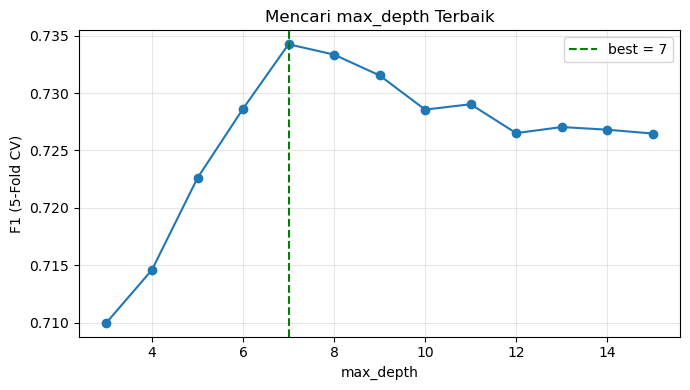

In [24]:
# Cari max_depth terbaik (5-Fold CV) memakai metrik F1
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor = {}
for d in range(3, 16):
    model = DecisionTreeClassifier(criterion='entropy', max_depth=d,
                                   min_samples_leaf=20, random_state=42)
    skor[d] = cross_val_score(model, X_train_bal, y_train_bal, cv=cv, scoring='f1').mean()

best_depth = max(skor, key=skor.get)
print(f"max_depth terbaik: {best_depth} (F1 CV = {skor[best_depth]:.3f})")

plt.figure(figsize=(7,4))
plt.plot(list(skor.keys()), list(skor.values()), 'o-')
plt.axvline(best_depth, ls='--', color='green', label=f'best = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('F1 (5-Fold CV)')
plt.title('Mencari max_depth Terbaik'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('02_tuning_depth.png', dpi=150); plt.show()

In [25]:
# Latih model final C4.5
model_c45 = DecisionTreeClassifier(
    criterion='entropy',        # C4.5 berbasis entropi
    max_depth=best_depth,
    min_samples_leaf=20,
    random_state=42)

model_c45.fit(X_train_bal, y_train_bal)
print(f"Model C4.5 selesai dilatih (max_depth={best_depth}).")

Model C4.5 selesai dilatih (max_depth=7).


## 8. Evaluasi Model (pada Data Testing)

In [26]:
y_pred = model_c45.predict(X_test)
y_prob = model_c45.predict_proba(X_test)[:, 1]

print(f"Accuracy          : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred)*100:.2f}%  (adil utk data tdk seimbang)")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_prob):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Diabetes', 'Diabetes']))

Accuracy          : 68.12%
Balanced Accuracy : 72.13%  (adil utk data tdk seimbang)
ROC-AUC           : 0.798

Classification Report:
                precision    recall  f1-score   support

Tidak Diabetes       0.94      0.66      0.77     38012
      Diabetes       0.32      0.78      0.46      7945

      accuracy                           0.68     45957
     macro avg       0.63      0.72      0.62     45957
  weighted avg       0.83      0.68      0.72     45957



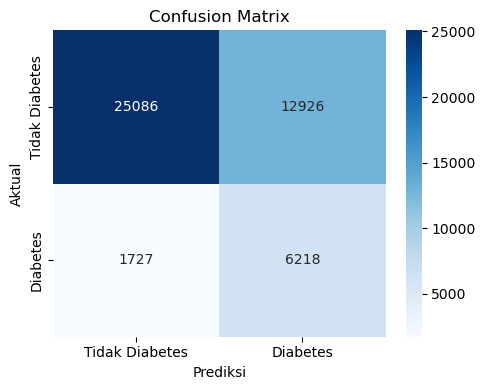

In [27]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Diabetes','Diabetes'],
            yticklabels=['Tidak Diabetes','Diabetes'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion Matrix')
plt.tight_layout(); plt.savefig('03_confusion_matrix.png', dpi=150); plt.show()

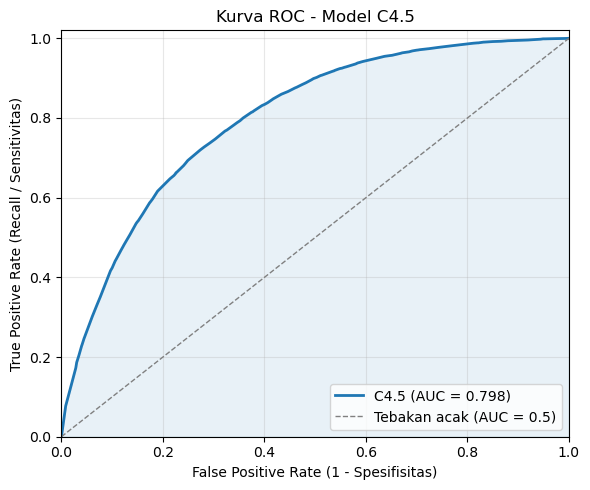

Nilai AUC (Area Under Curve): 0.798


In [28]:
# Hitung titik-titik kurva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#1f77b4', lw=2, label=f'C4.5 (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, ls='--', label='Tebakan acak (AUC = 0.5)')
plt.fill_between(fpr, tpr, alpha=0.1, color='#1f77b4')
plt.xlim([0, 1]); plt.ylim([0, 1.02])
plt.xlabel('False Positive Rate (1 - Spesifisitas)')
plt.ylabel('True Positive Rate (Recall / Sensitivitas)')
plt.title('Kurva ROC - Model C4.5')
plt.legend(loc='lower right'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('06_roc_curve.png', dpi=150); plt.show()

print(f"Nilai AUC (Area Under Curve): {roc_auc:.3f}")

## 9. Visualisasi Pohon & Feature Importance

   Fitur  Importance
  HighBP    0.394696
 GenHlth    0.289088
     Age    0.133847
     BMI    0.127096
HighChol    0.055272


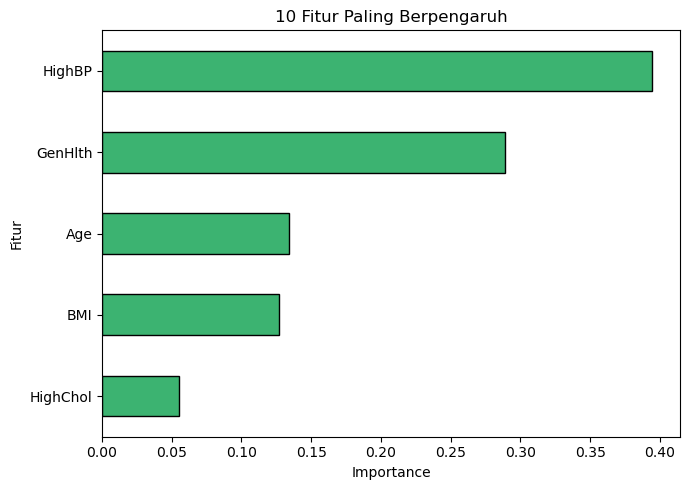

In [29]:
# Feature importance
imp = pd.DataFrame({'Fitur': X.columns,
                    'Importance': model_c45.feature_importances_}
                  ).sort_values('Importance', ascending=False)
print(imp.head(10).to_string(index=False))

plt.figure(figsize=(7,5))
imp.head(10).set_index('Fitur')['Importance'].plot(
    kind='barh', color='mediumseagreen', edgecolor='black')
plt.gca().invert_yaxis()
plt.title('10 Fitur Paling Berpengaruh'); plt.xlabel('Importance')
plt.tight_layout(); plt.savefig('04_feature_importance.png', dpi=150); plt.show()

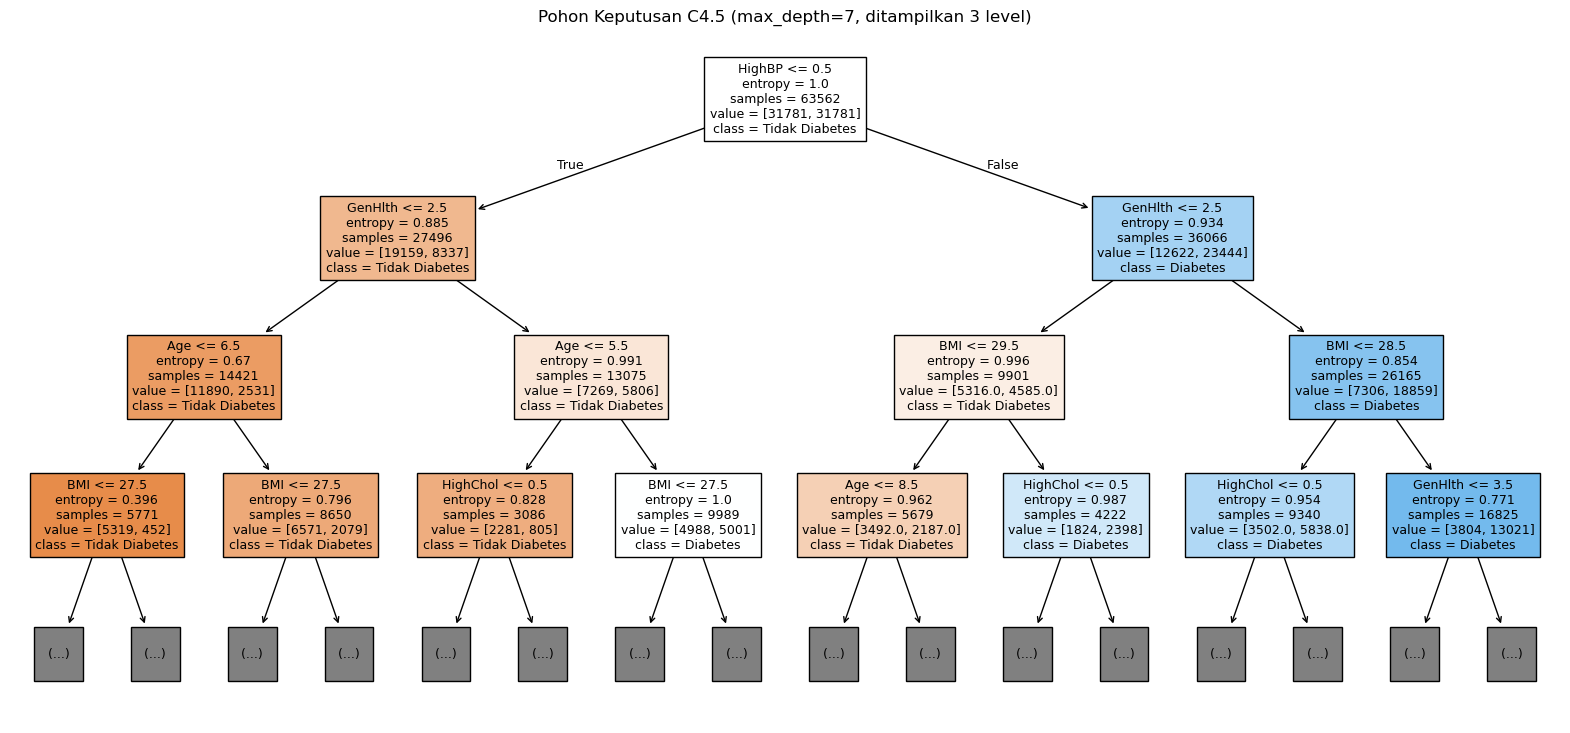

In [30]:
# Visualisasi pohon (dibatasi 3 level agar mudah dibaca)
plt.figure(figsize=(20,9))
plot_tree(model_c45, feature_names=list(X.columns),
          class_names=['Tidak Diabetes','Diabetes'],
          filled=True, max_depth=3, fontsize=9)
plt.title(f'Pohon Keputusan C4.5 (max_depth={best_depth}, ditampilkan 3 level)')
plt.savefig('05_pohon_c45.png', dpi=150, bbox_inches='tight'); plt.show()

In [31]:
with open('model_c45_diabetes.pkl', 'wb') as f:
    pickle.dump(model_c45, f)
print("Model disimpan sebagai 'model_c45_diabetes.pkl'")

# Cara memuat kembali:
# with open('model_c45_diabetes.pkl', 'rb') as f:
#     model = pickle.load(f)

Model disimpan sebagai 'model_c45_diabetes.pkl'


## Ringkasan

- **Preprocessing**: hapus duplikat → ubah ke biner (Tidak Diabetes vs Diabetes).
- **Balancing**: undersampling pada data training saja → kelas seimbang 50:50.
- **Model**: C4.5 = `DecisionTreeClassifier(criterion='entropy')`.
- Test set dibiarkan tidak seimbang agar evaluasi realistis; gunakan **Balanced Accuracy** & **ROC-AUC** sebagai patokan utama, bukan accuracy biasa.